## **02 -- Patient-grouped nested validation of the SMM model (24-hour prediction point)**

**Place in the framework.** This notebook serves stages E7 to E8 for the main SMM model, gate P3 and return R1 (maternal death). Each section starts with a **Framework** line.

| Section | Framework | What it produces |
|---|---|---|
| 1-6 | E1 · E7 · E6 · E8 | Configuration, predictors, populations, pipeline, metrics, reports |
| 7 | P3 | Riley sample-size criteria for SMM (observed) and maternal death (assumed) |
| 8 | E8 · P4 | Main SMM model at 24 h: the full-label result used by gate P4 |
| 9 | P3 → R1 | Maternal death: feasibility only (no model trained); return R1 to SMM |
| 10 | E9 | Sensitivity analyses of the main model |

Framework codes: E1 Governance and configuration · E2 Universe and population · E3 Outcome definition · E4 Count audit ·
E5 Unit of analysis and overlap · E6 Prediction point and window · E7 Predictors · E8 Modeling, validation and metrics ·
E9 Sensitivity and robustness · E10 From classification to action · E11 Reporting. Gates P1-P4; returns R1-R4; gate-P4 criteria
C1-C4 (C1 events already present, C2 outcome with time, C3 detection bias, C4 stability over time). The full description of each
stage is in the framework document; the map of every script and notebook is in the README (section *Framework map*).


**Purpose.** Estimate the performance of the severe maternal morbidity (SMM) model at the 24-hour prediction point with a
patient-grouped nested validation. It reads the tables built by `sql/05_predictors/`
and does **not** modify the database or any other notebook.

**Design**

| Element | Choice |
|---|---|
| Population | Eligible delivery hospitalizations (alive and in hospital at admission + 24 h) |
| Outcome | `smm_any` (CDC SMM indicators on ICD-9-CM and ICD-10-CM) |
| Predictors | Main model: hemoglobin, creatinine (+ missingness indicator), age and admission variables |
| Outer evaluation | `StratifiedGroupKFold` **by `subject_id`**, repeated; no patient is ever on both sides of a split |
| Preprocessing | Percentile clipping, median imputation, scaling, one-hot encoding: **fitted on training data only, inside every fit** |
| Learners | Logistic regression (reference), random forest, extra trees, XGBoost, and the **stacked ensemble** (logistic meta-learner on out-of-fold predictions) |
| Tuning | Small grids (6 configurations per algorithm), inner patient-grouped CV, metric = average precision. Class weights are grid options; **no resampling (no SMOTE)**. The grids were widened once in preliminary runs because several learners chose values at the edge of the grid (documented in the code) |
| Calibration | Platt recalibration estimated on inner out-of-fold predictions (never on the outer test patients) |
| Uncertainty | Cluster bootstrap by patient (B = 1000), paired differences against logistic regression, SD across repeats |
| Clinical usefulness | Net benefit (decision curve), sensitivity / PPV in the top 5 % and 10 % of predicted risk |
| Sample size | Riley et al. criteria for Model B (observed) and Model A (assumed R2, **no model is trained for Model A**) |

**Data-use rules.** Only aggregate results are printed. No identifier or patient-level row is displayed, exported or
saved. The only files written are the aggregate text reports `data/outputs_*.txt` (tables of metrics and counts).
Do **not** add cells that print or export rows.

**Run order.** Run all cells top to bottom. First set `QUICK = True` for a smoke test (minutes), then `QUICK = False`
for the real run (expect roughly 15-40 minutes for the main analysis, depending on the machine; the notebook prints a
projected time after the first outer fold). Each analysis also saves its report as `outputs_<name>.txt` in `data/`, so the output can be read without
truncation.

### **1. Libraries, connection and settings**

> **Framework:** E1 Governance and configuration. Fixed seed, folds, repeats and bootstrap replicates; reference counts.

In [1]:
import os, sys, time, math, warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# notebooks/ -> project root is one level up
sys.path.append(os.path.abspath(os.path.join("..")))
import libraries.database as db_lib
engine = db_lib.get_connect_database()

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# ----------------------------------------------------------------------------- settings
QUICK        = False        # True = smoke test (small forests, 1 repeat, B = 50). Never report QUICK numbers.
SEED         = 20260101
OUTER_FOLDS  = 5
N_REPEATS    = 3            # repeats of the outer grouped CV (development instability)
INNER_FOLDS  = 3
BOOT         = 1000         # cluster bootstrap replicates for the main analysis
BOOT_SENS    = 300          # replicates for the sensitivity analyses
N_JOBS       = -1
N_TREES      = 300
XGB_TREES    = 200
APPLY_LIMITS = True         # set values outside the plausibility limits of the dictionary to missing
CAT_COLS     = ["ethnicity", "insurance", "language", "admission_type", "admission_location"]
DCA_T        = [0.005, 0.01, 0.02, 0.03, 0.05, 0.10, 0.15, 0.20]
EXPECTED     = {"eligible_deliveries": 19383, "smm": 445, "deaths": 3}   # from the audit counts (Q-F / Q-G)

if QUICK:
    OUTER_FOLDS, N_REPEATS, BOOT, BOOT_SENS = 3, 1, 50, 30
    N_TREES, XGB_TREES = 60, 50
print(f"QUICK={QUICK}  outer={OUTER_FOLDS}x{N_REPEATS}  inner={INNER_FOLDS}  B={BOOT}  trees={N_TREES}")

QUICK=False  outer=5x3  inner=3  B=1000  trees=300


### **2. Load the predictor table and the final dictionary**

> **Framework:** E7 Predictors (dictionary, coverage roles, plausibility limits, missingness indicators) and E4 / P1 (check against the reference counts).

`predictors_24h_v2` has one row per obstetric hospitalization with the predictors observed in the window
(admission - 24 h, admission + 24 h). `predictor_dictionary_final_v2` assigns every variable its role
(`main model`, `ICU sensitivity only`, `laboratory sensitivity ...`) and its plausibility limits.
Only counts are printed.

In [2]:
df = pd.read_sql("SELECT * FROM mimiciv.predictors_24h_v2", engine)
dic = pd.read_sql("""SELECT variable, model_role_final, missingness_indicator_main, plausible_low, plausible_high,
                            n_eligible_delivery, coverage_pct
                     FROM mimiciv.predictor_dictionary_final_v2""", engine)

for c in ["eligible_24h", "icu_in_24h", "is_delivery_v2", "smm_any", "died_same_admission"]:
    df[c] = df[c].fillna(False).astype(bool)
df["admittime"] = pd.to_datetime(df["admittime"])

VAR_MAIN = dic.loc[dic.model_role_final == "main model", "variable"].tolist()
VAR_ICU  = dic.loc[dic.model_role_final == "ICU sensitivity only", "variable"].tolist()
VAR_LAB  = dic.loc[dic.model_role_final.str.startswith("laboratory sensitivity"), "variable"].tolist()
IND_MAIN = dic.loc[dic.missingness_indicator_main.fillna(False).astype(bool), "variable"].tolist()

print("Dictionary roles ->", {"main": VAR_MAIN, "ICU only": len(VAR_ICU), "lab sensitivity": len(VAR_LAB),
                              "missingness indicator in main model": IND_MAIN})

# Plausibility limits (proposals pending clinical confirmation): out-of-range values become missing
if APPLY_LIMITS:
    n_set = {}
    for _, r in dic.dropna(subset=["plausible_low", "plausible_high"]).iterrows():
        v = r["variable"]
        if v in df.columns:
            bad = (df[v] < r["plausible_low"]) | (df[v] > r["plausible_high"])
            n_set[v] = int(bad.sum())
            df.loc[bad, v] = np.nan
    print("Values set to missing by plausibility limits (count per variable):", n_set)

# Missingness indicators (computed row by row from the raw value: no information crosses patients)
for v in set(IND_MAIN + VAR_LAB + VAR_ICU):
    df[f"{v}_missing"] = df[v].isna().astype(int)
df["icu_in_24h_bin"] = df["icu_in_24h"].astype(int)
df["y"] = df["smm_any"].astype(int)

# Audit checks against the counts already certified (aggregate only)
elig = df[df.eligible_24h & df.is_delivery_v2]
chk = {"eligible_deliveries": len(elig), "smm": int(elig.smm_any.sum()), "deaths": int(elig.died_same_admission.sum())}
for k, v in chk.items():
    print(f"{k}: {v}  (expected {EXPECTED[k]})  [{'OK' if v == EXPECTED[k] else 'CHECK: differs from the audit counts'}]")
print("Eligible any obstetric admissions:", int(df.eligible_24h.sum()),
      "| SMM:", int(df[df.eligible_24h].smm_any.sum()), "| deaths:", int(df[df.eligible_24h].died_same_admission.sum()))

Dictionary roles -> {'main': ['hemoglobin', 'creatinine'], 'ICU only': 14, 'lab sensitivity': 11, 'missingness indicator in main model': ['creatinine']}
Values set to missing by plausibility limits (count per variable): {'hemoglobin': 0, 'hematocrit': 0, 'creatinine': 1}
eligible_deliveries: 19383  (expected 19383)  [OK]
smm: 445  (expected 445)  [OK]
deaths: 3  (expected 3)  [OK]
Eligible any obstetric admissions: 23625 | SMM: 814 | deaths: 5


### **3. Analysis datasets and feature sets**

> **Framework:** E6 Prediction point and window. Population and label of each analysis.

Each analysis is a (population, feature set, label) specification:

| Name | Population | Features |
|---|---|---|
| `main` | Eligible delivery hospitalizations | Main-model variables of the dictionary (hemoglobin, creatinine), creatinine missingness indicator, age, categorical admission variables |
| `first_admission` | Index (first) delivery hospitalization of each patient, if eligible | as `main` |
| `any_obstetric` | Eligible obstetric hospitalizations (delivery or not) | as `main` |
| `labs_extended` | as `main` | `main` + hematocrit and the other laboratory variables, each with a missingness indicator |
| `icu_vars` | as `main` | `main` + the ICU-only variables (each with a missingness indicator) + `icu_in_24h` |
| `label_ge2` | as `main` | as `main`, outcome = two or more SMM indicators (`smm_ge2`) |
| `no_icu_24h` | Eligible deliveries **without** an ICU admission in the first 24 h | as `main` |
| `icd10_only` | Eligible deliveries whose diagnoses are all ICD-10-CM (no ICD-9-CM diagnosis) | as `main` |

In [3]:
def make_spec(name):
    d = df[df.eligible_24h].copy()
    num = ["age_at_admission"] + VAR_MAIN
    binc = [f"{v}_missing" for v in IND_MAIN]
    label = "y"
    if name in ("main", "labs_extended", "icu_vars", "label_ge2", "no_icu_24h", "icd10_only"):
        d = d[d.is_delivery_v2]
        if name == "no_icu_24h":
            d = d[~d.icu_in_24h]
    elif name == "first_admission":
        first = df[df.is_delivery_v2].sort_values(["subject_id", "admittime", "hadm_id"]).drop_duplicates("subject_id")
        d = d[d.hadm_id.isin(first.hadm_id)]
    elif name == "any_obstetric":
        pass
    else:
        raise ValueError(name)
    if name == "icd10_only":
        ver = pd.read_sql("SELECT hadm_id, has_icd9_dx, has_icd10_dx FROM mimiciv.cohort_obstetric_v2", engine)
        ver["has_icd9_dx"] = ver["has_icd9_dx"].fillna(False).astype(bool)
        ver["has_icd10_dx"] = ver["has_icd10_dx"].fillna(False).astype(bool)
        keep = ver.loc[ver.has_icd10_dx & ~ver.has_icd9_dx, "hadm_id"]
        d = d[d.hadm_id.isin(keep)]
    if name == "labs_extended":
        num = num + VAR_LAB
        binc = binc + [f"{v}_missing" for v in VAR_LAB if f"{v}_missing" not in binc]
    if name == "icu_vars":
        num = num + VAR_ICU
        binc = binc + [f"{v}_missing" for v in VAR_ICU] + ["icu_in_24h_bin"]
    if name == "label_ge2":
        g2 = pd.read_sql("SELECT hadm_id, smm_ge2 FROM mimiciv.cohort_obstetric_v2", engine)
        g2["smm_ge2"] = g2["smm_ge2"].fillna(False).astype(bool).astype(int)
        d = d.merge(g2, on="hadm_id", how="left")
        d["y_ge2"] = d["smm_ge2"].fillna(0).astype(int)
        label = "y_ge2"
    # drop columns that do not exist or never vary (a constant indicator carries no information)
    num  = [c for c in dict.fromkeys(num) if c in d.columns]
    binc = [c for c in dict.fromkeys(binc) if c in d.columns and d[c].nunique() > 1]
    cat  = [c for c in CAT_COLS if c in d.columns]
    d = d.reset_index(drop=True)
    return dict(name=name, data=d, num=num, bin=binc, cat=cat, label=label)

for nm in ["main", "first_admission", "any_obstetric", "labs_extended", "icu_vars", "no_icu_24h", "icd10_only"]:
    sp = make_spec(nm)
    d = sp["data"]
    print(f"{nm:16s} admissions={len(d):6d}  patients={d.subject_id.nunique():6d}  events={int(d[sp['label']].sum()):4d}  "
          f"numeric={len(sp['num'])}  binary={len(sp['bin'])}  categorical={len(sp['cat'])}")

main             admissions= 19383  patients= 13710  events= 445  numeric=3  binary=1  categorical=5
first_admission  admissions= 13701  patients= 13701  events= 356  numeric=3  binary=1  categorical=5
any_obstetric    admissions= 23625  patients= 14602  events= 814  numeric=3  binary=1  categorical=5
labs_extended    admissions= 19383  patients= 13710  events= 445  numeric=14  binary=12  categorical=5
icu_vars         admissions= 19383  patients= 13710  events= 445  numeric=17  binary=16  categorical=5
no_icu_24h       admissions= 19268  patients= 13632  events= 355  numeric=3  binary=1  categorical=5
icd10_only       admissions=  8864  patients=  7070  events= 271  numeric=3  binary=1  categorical=5


### **4. Core functions (preprocessing, learners, nested tuning, stacking, calibration)**

> **Framework:** E8 Modeling, validation and metrics. Everything that learns from data stays inside the training part of each split (gate P2: no patient on both sides).

Everything that learns from data is inside the training portion of each split:

* `Winsor` clips each numeric column to the 0.5th-99.5th percentiles *of the training data*.
* The median imputer, the scaler and the one-hot encoder are fitted inside a `Pipeline`, once per fit.
* Hyperparameters are chosen by **inner patient-grouped CV** (average precision of the pooled out-of-fold predictions).
* The meta-learner of the ensemble is trained on the **out-of-fold** predictions of the base learners (never on in-sample predictions).
* The Platt calibrator is trained on out-of-fold predictions of the training patients; the outer test patients are only scored.

In [4]:
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def expit(z):
    return 1.0 / (1.0 + np.exp(-z))

class Winsor(BaseEstimator, TransformerMixin):
    """Clip each column to training percentiles (fit on the training data only)."""
    def __init__(self, lo=0.5, hi=99.5):
        self.lo = lo; self.hi = hi
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_ = np.nanpercentile(X, self.lo, axis=0)
        self.hi_ = np.nanpercentile(X, self.hi, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)

def make_prep(num, binc, cat):
    parts = [("num", Pipeline([("w", Winsor()),
                               ("imp", SimpleImputer(strategy="median", keep_empty_features=True)),
                               ("sc", StandardScaler())]), num)]
    if binc:
        parts.append(("bin", "passthrough", binc))
    if cat:
        parts.append(("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                                       ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                            min_frequency=0.01, sparse_output=False))]), cat))
    return ColumnTransformer(parts)

def prep_frame(d, num, binc, cat):
    X = d[num + binc + cat].copy()
    for c in cat:
        X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
    return X

# Small prespecified grids (class weights are options; no resampling)
GRID = {
    # The grids cover values beyond those most often chosen in preliminary runs, so that the selected value
    # is not at the edge of the grid (ET depth, RF depth and XGB depth; class weights remain options).
    "LR":  [dict(C=C, cw=cw) for C in (0.01, 0.1, 1.0) for cw in (None, "balanced")],
    "RF":  [dict(depth=dp, cw=cw) for dp in (2, 4, 8) for cw in (None, "balanced_subsample")],
    "ET":  [dict(depth=dp, cw=cw) for dp in (4, 8, 12) for cw in (None, "balanced_subsample")],
    "XGB": [dict(depth=dp, spw=sp) for dp in (1, 2, 4) for sp in (1, "sqrt")],
}
MODELS = ["LR", "RF", "ET", "XGB", "Stack", "Stack_raw"]
BOOT_MODELS = ["LR", "RF", "ET", "XGB", "Stack"]
PAIRS = [("RF", "LR"), ("ET", "LR"), ("XGB", "LR"), ("Stack", "LR"), ("Stack", "XGB")]

def cfg_str(c):
    return ",".join(f"{k}={v}" for k, v in c.items())

def make_clf(name, cfg, ytr, seed):
    if name == "LR":
        return LogisticRegression(C=cfg["C"], class_weight=cfg["cw"], max_iter=3000)
    if name == "RF":
        return RandomForestClassifier(n_estimators=N_TREES, max_depth=cfg["depth"], min_samples_leaf=20,
                                      class_weight=cfg["cw"], n_jobs=N_JOBS, random_state=seed)
    if name == "ET":
        return ExtraTreesClassifier(n_estimators=N_TREES, max_depth=cfg["depth"], min_samples_leaf=20,
                                    class_weight=cfg["cw"], n_jobs=N_JOBS, random_state=seed)
    if name == "XGB":
        pos = max(int(ytr.sum()), 1); neg = max(len(ytr) - pos, 1)
        spw = math.sqrt(neg / pos) if cfg["spw"] == "sqrt" else 1.0
        return XGBClassifier(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=cfg["depth"], subsample=0.8,
                             colsample_bytree=0.8, min_child_weight=5, scale_pos_weight=spw, eval_metric="logloss",
                             tree_method="hist", n_jobs=N_JOBS if N_JOBS and N_JOBS > 0 else 0, random_state=seed)
    raise ValueError(name)

def fit_predict(name, cfg, prep, Xtr, ytr, Xte, seed):
    pipe = Pipeline([("prep", clone(prep)), ("clf", make_clf(name, cfg, ytr, seed))])
    pipe.fit(Xtr, ytr)
    return pipe.predict_proba(Xte)[:, 1]

def platt(o, t, ytr):
    c = LogisticRegression(penalty=None, max_iter=1000).fit(logit(o).reshape(-1, 1), ytr)
    return c.predict_proba(logit(t).reshape(-1, 1))[:, 1]

def tune_stack_calibrate(Xtr, ytr, gtr, Xte, prep, seed):
    """Inside one outer training set: tune, build out-of-fold predictions, stack, calibrate; score the outer test set."""
    inner = list(StratifiedGroupKFold(INNER_FOLDS, shuffle=True, random_state=seed).split(Xtr, ytr, gtr))
    names = list(GRID)
    chosen, oof, pred_te = {}, {}, {}
    for name in names:
        best = None
        for cfg in GRID[name]:
            o = np.zeros(len(ytr))
            for tr, va in inner:
                o[va] = fit_predict(name, cfg, prep, Xtr.iloc[tr], ytr[tr], Xtr.iloc[va], seed)
            ap = average_precision_score(ytr, o)
            if best is None or ap > best[0]:
                best = (ap, cfg, o)
        chosen[name] = best[1]; oof[name] = best[2]
        pred_te[name] = fit_predict(name, best[1], prep, Xtr, ytr, Xte, seed)
    # explicit stacking: logistic meta-learner on out-of-fold base predictions (C = 0.1 as in the original framework)
    Z_oof = np.column_stack([logit(oof[n]) for n in names])
    Z_te = np.column_stack([logit(pred_te[n]) for n in names])
    meta = LogisticRegression(C=0.1, max_iter=2000).fit(Z_oof, ytr)
    stack_te_raw = meta.predict_proba(Z_te)[:, 1]
    # cross-fitted meta out-of-fold predictions -> calibrator never sees the predictions of its own training rows
    mo = np.zeros(len(ytr))
    for tr, va in StratifiedGroupKFold(INNER_FOLDS, shuffle=True, random_state=seed + 1).split(Z_oof, ytr, gtr):
        m = LogisticRegression(C=0.1, max_iter=2000).fit(Z_oof[tr], ytr[tr])
        mo[va] = m.predict_proba(Z_oof[va])[:, 1]
    out = {n: platt(oof[n], pred_te[n], ytr) for n in names}
    out["Stack"] = platt(mo, stack_te_raw, ytr)
    out["Stack_raw"] = stack_te_raw
    return out, chosen

def run_cv(spec, label=""):
    d = spec["data"]
    X = prep_frame(d, spec["num"], spec["bin"], spec["cat"])
    y = d[spec["label"]].values.astype(int)
    g = d["subject_id"].values
    prep = make_prep(spec["num"], spec["bin"], spec["cat"])
    n = len(y)
    preds = {m: np.full((N_REPEATS, n), np.nan) for m in MODELS}
    chosen_log = []
    split_log = []
    t0 = time.time(); done = 0; total = N_REPEATS * OUTER_FOLDS
    for r in range(N_REPEATS):
        outer = StratifiedGroupKFold(OUTER_FOLDS, shuffle=True, random_state=SEED + r)
        for k, (tr, te) in enumerate(outer.split(X, y, g)):
            assert len(set(g[tr]) & set(g[te])) == 0, "patient present in training and test"
            split_log.append(dict(repeat=r + 1, fold=k + 1,
                                  train_adm=len(tr), train_pat=len(set(g[tr])), train_events=int(y[tr].sum()),
                                  train_event_pat=len(set(g[tr][y[tr] == 1])),
                                  test_adm=len(te), test_pat=len(set(g[te])), test_events=int(y[te].sum()),
                                  test_event_pat=len(set(g[te][y[te] == 1])), shared_patients=0))
            out, chosen = tune_stack_calibrate(X.iloc[tr], y[tr], g[tr], X.iloc[te], prep, SEED + 100 * r + k)
            for m in MODELS:
                preds[m][r, te] = out[m]
            for nme, cfg in chosen.items():
                chosen_log.append((nme, cfg_str(cfg)))
            done += 1
            if done == 1:
                el = time.time() - t0
                print(f"[{spec['name']}] first outer fold took {el/60:.1f} min -> projected total about {el*total/60:.0f} min")
    print(f"[{spec['name']}] cross-validation finished in {(time.time()-t0)/60:.1f} min; "
          f"every admission scored exactly once per repeat: {bool(np.isfinite(preds['Stack']).all())}")
    return dict(spec=spec, y=y, g=g, preds=preds, chosen=chosen_log, X=X, prep=prep, splits=pd.DataFrame(split_log))

### **5. Metrics, cluster bootstrap and paired differences**

> **Framework:** E8 Modeling, validation and metrics. Discrimination, calibration, clinical usefulness, patient-level bootstrap.

All metrics are computed on the pooled out-of-fold predictions of each repeat and then averaged over repeats.
The bootstrap resamples **patients** (all admissions of a patient move together) and recomputes every metric with
patient-count weights, so intervals reflect the repeated-admission structure. Differences against logistic
regression use the **same** bootstrap samples (paired).

In [5]:
def citl(y, z, w):
    """Calibration-in-the-large: intercept with the slope fixed at 1 (weighted Newton)."""
    a = 0.0
    for _ in range(40):
        pr = expit(z + a)
        g = np.sum(w * (y - pr)); h = np.sum(w * pr * (1 - pr))
        if h < 1e-12:
            break
        step = g / h; a += step
        if abs(step) < 1e-9:
            break
    return a

def calib_slope(y, z, w):
    """Calibration slope (weighted logistic recalibration, Newton)."""
    a, b = 0.0, 1.0
    for _ in range(40):
        pr = expit(a + b * z)
        r = w * (y - pr); v = w * pr * (1 - pr)
        gr = np.array([r.sum(), (r * z).sum()])
        H = np.array([[v.sum(), (v * z).sum()], [(v * z).sum(), (v * z * z).sum()]])
        try:
            dlt = np.linalg.solve(H, gr)
        except np.linalg.LinAlgError:
            break
        a += dlt[0]; b += dlt[1]
        if np.abs(dlt).max() < 1e-9:
            break
    return b

def top_threshold(p, w, k):
    order = np.argsort(-p)
    cw = np.cumsum(w[order])
    idx = int(np.searchsorted(cw, k * cw[-1]))
    return p[order][min(idx, len(p) - 1)]

def metrics_one(y, p, w):
    z = logit(p)
    m = {}
    m["auroc"] = roc_auc_score(y, p, sample_weight=w)
    m["auprc"] = average_precision_score(y, p, sample_weight=w)
    m["brier"] = float(np.average((p - y) ** 2, weights=w))
    m["slope"] = calib_slope(y, z, w)
    m["citl"] = citl(y, z, w)
    m["oe"] = float(np.sum(w * y) / np.sum(w * p))
    edges = np.quantile(p, np.linspace(0, 1, 11)[1:-1])
    bins = np.searchsorted(edges, p)
    W = w.sum(); ece = 0.0
    for b in range(10):
        mk = bins == b; wb = w[mk].sum()
        if wb > 0:
            ece += wb / W * abs(np.sum(w[mk] * y[mk]) / wb - np.sum(w[mk] * p[mk]) / wb)
    m["ece"] = ece
    ev = np.sum(w * y)
    for k in (0.05, 0.10):
        sel = p >= top_threshold(p, w, k)
        m[f"sens_top{int(k*100)}"] = np.sum(w[sel] * y[sel]) / ev
        m[f"ppv_top{int(k*100)}"] = np.sum(w[sel] * y[sel]) / np.sum(w[sel])
    for pt in DCA_T:
        sel = p >= pt
        tp = np.sum(w[sel] * y[sel]); fp = np.sum(w[sel] * (1 - y[sel]))
        m[f"nb_{pt}"] = tp / W - fp / W * pt / (1 - pt)
    return m

def all_metrics(y, preds, w, models, strata):
    """Metrics for each model, averaged over repeats. Returns dict[(model, metric)] and the per-repeat list."""
    per = []
    for r in range(N_REPEATS):
        cur = {}
        for mname in models:
            for k, v in metrics_one(y, preds[mname][r], w).items():
                cur[(mname, k)] = v
        prev = np.sum(w * y) / w.sum()
        for pt in DCA_T:
            cur[("TreatAll", f"nb_{pt}")] = prev - (1 - prev) * pt / (1 - pt)
        for sname, mask in strata.items():
            for mname in ("LR", "Stack"):
                if mname not in models:
                    continue
                wm = w[mask]; ym = y[mask]; pm = preds[mname][r][mask]
                if np.sum(wm * ym) >= 1 and np.sum(wm * (1 - ym)) >= 1:
                    cur[(mname, f"auroc_{sname}")] = roc_auc_score(ym, pm, sample_weight=wm)
                    cur[(mname, f"auprc_{sname}")] = average_precision_score(ym, pm, sample_weight=wm)
                else:
                    cur[(mname, f"auroc_{sname}")] = np.nan
                    cur[(mname, f"auprc_{sname}")] = np.nan
        per.append(cur)
    keys = per[0].keys()
    mean = {k: float(np.nanmean([c[k] for c in per])) if not all(np.isnan(c[k]) for c in per) else np.nan for k in keys}
    return mean, per

def bootstrap(res, B, strata, seed):
    y, g, preds = res["y"], res["g"], res["preds"]
    ug, inv = np.unique(g, return_inverse=True)
    G = len(ug)
    rng = np.random.default_rng(seed)
    out = {}
    t0 = time.time()
    for b in range(B):
        cnt = np.bincount(rng.integers(0, G, G), minlength=G)
        w = cnt[inv].astype(float)
        if np.sum(w * y) < 1:
            continue
        mean, _ = all_metrics(y.astype(float), preds, w, BOOT_MODELS, strata)
        for k, v in mean.items():
            out.setdefault(k, []).append(v)
        for a_, b_ in PAIRS:            # paired differences (same bootstrap sample)
            for met in ("auroc", "auprc", "brier") + tuple(f"nb_{pt}" for pt in DCA_T):
                out.setdefault((f"{a_}-{b_}", met), []).append(mean[(a_, met)] - mean[(b_, met)])
        if b == 4:
            el = time.time() - t0
            print(f"  bootstrap: 5 replicates took {el:.0f} s -> projected {el*B/5/60:.1f} min for B={B}")
    return {k: np.array(v) for k, v in out.items()}

### **6. Reporting function**

> **Framework:** E8 and E11 Reporting. Aggregate reports only.

Prints aggregate tables only: discrimination, calibration, paired differences against logistic regression, the share of
events captured in the top 5 % / 10 % of predicted risk, net benefit, development instability across repeats and the
hyperparameters chosen in the inner loops.

In [6]:
def _ci(boot, key, d=3):
    a = boot.get(key)
    if a is None or len(a) < 20:
        return ""
    lo, hi = np.nanpercentile(a, [2.5, 97.5])
    return f" ({lo:.{d}f}-{hi:.{d}f})"

def decile_table(res, models=("LR", "Stack")):
    y = res["y"].astype(float)
    out = None
    for m in models:
        acc = []
        for r in range(N_REPEATS):
            p = res["preds"][m][r]
            edges = np.quantile(p, np.linspace(0, 1, 11)[1:-1])
            b = np.searchsorted(edges, p)
            acc.append(pd.DataFrame({"b": b, "p": p, "y": y}).groupby("b").agg(n=("y", "size"), pred=("p", "mean"), obs=("y", "mean")))
        mean = sum(acc) / len(acc)
        t = pd.DataFrame({"decile": mean.index + 1, "n": mean["n"].round(0).astype(int)}) if out is None else out
        t[f"{m}_pred"] = mean["pred"].round(4).values
        t[f"{m}_obs"] = mean["obs"].round(4).values
        out = t
    return out

def plot_calibration(res):
    import matplotlib.pyplot as plt
    t = decile_table(res)
    fig, ax = plt.subplots(figsize=(5, 5))
    mx = float(max(t["LR_pred"].max(), t["LR_obs"].max(), t["Stack_pred"].max(), t["Stack_obs"].max())) * 1.1
    ax.plot([0, mx], [0, mx], color="grey", lw=1, ls="--", label="ideal")
    ax.plot(t["LR_pred"], t["LR_obs"], "o-", label="Logistic regression")
    ax.plot(t["Stack_pred"], t["Stack_obs"], "s-", label="Stacked ensemble")
    ax.set_xlabel("Mean predicted risk (decile)"); ax.set_ylabel("Observed SMM rate")
    ax.set_title(f"Calibration by decile -- {res['spec']['name']}"); ax.legend(); plt.show()   # displayed only, not saved

def emit(name, fn):
    """Print the aggregate report and also keep it as a text file (aggregates only) so it can be shared without truncation."""
    import io, contextlib
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        fn()
    text = buf.getvalue()
    print(text)
    path = f"../data/outputs_{name}.txt"
    with open(path, "w", encoding="utf-8") as fh:
        fh.write(text)
    print(f"[aggregate report saved as data/{os.path.basename(path)}  ({len(text)} characters)]")

def run_analysis(name, B):
    spec = make_spec(name)
    res = run_cv(spec)
    d = spec["data"]
    strata = {}
    if name == "main":
        strata = {"icu1": d["icu_in_24h"].values.astype(bool), "icu0": ~d["icu_in_24h"].values.astype(bool)}
    y = res["y"].astype(float)
    res["point"], res["per"] = all_metrics(y, res["preds"], np.ones(len(y)), MODELS + [], strata)
    res["boot"] = bootstrap(res, B, strata, SEED + 7)
    res["strata"] = strata
    return res

def report(res):
    sp = res["spec"]; d = sp["data"]; y = res["y"]
    pt, per, bt = res["point"], res["per"], res["boot"]
    n, ev, npat = len(y), int(y.sum()), d.subject_id.nunique()
    print("=" * 110)
    print(f"ANALYSIS {sp['name']}: {n} admissions, {npat} patients, {ev} events ({100*ev/n:.2f}%), "
          f"numeric={len(sp['num'])}, binary={len(sp['bin'])}, categorical={len(sp['cat'])}")
    print(f"Repeats={N_REPEATS}, outer folds={OUTER_FOLDS}, inner folds={INNER_FOLDS}, bootstrap B={len(next(iter(bt.values()))) if bt else 0}, QUICK={QUICK}")
    print("=" * 110)

    sl = res["splits"]
    print("\n[0] Patients per outer partition (repeat 1 shown; every split verified to share no patient between training and test)")
    print(sl[sl.repeat == 1].drop(columns=["repeat"]).to_string(index=False))
    print(f"    Across all {len(sl)} splits: test patients per fold {sl.test_pat.min()}-{sl.test_pat.max()}, "
          f"event-bearing test patients per fold {sl.test_event_pat.min()}-{sl.test_event_pat.max()}, "
          f"patients present on both sides: {int(sl.shared_patients.sum())}")

    rows = []
    for m in MODELS:
        r = {"model": m}
        for met, dd in [("auroc", 3), ("auprc", 3), ("brier", 5)]:
            r[met] = f"{pt[(m, met)]:.{dd}f}" + (_ci(bt, (m, met), dd) if m in BOOT_MODELS else "")
        r["sd_auroc_repeats"] = f"{np.std([c[(m,'auroc')] for c in per], ddof=1):.4f}" if len(per) > 1 else "n/a"
        r["sd_auprc_repeats"] = f"{np.std([c[(m,'auprc')] for c in per], ddof=1):.4f}" if len(per) > 1 else "n/a"
        rows.append(r)
    print("\n[1] Discrimination and overall accuracy (mean over repeats; 95% cluster-bootstrap CI)")
    print(f"    prevalence = {y.mean():.4f}  (AUPRC of a non-informative model equals the prevalence)")
    print(pd.DataFrame(rows).to_string(index=False))

    rows = []
    for m in MODELS:
        r = {"model": m}
        for met, dd in [("slope", 2), ("citl", 2), ("oe", 2), ("ece", 4)]:
            r[met] = f"{pt[(m, met)]:.{dd}f}" + (_ci(bt, (m, met), dd) if m in BOOT_MODELS else "")
        rows.append(r)
    print("\n[2] Calibration (slope ideal 1; calibration-in-the-large ideal 0; O/E ideal 1; ECE with 10 quantile bins)")
    print(pd.DataFrame(rows).to_string(index=False))

    rows = []
    for a_, b_ in PAIRS:
        r = {"comparison (first minus second)": f"{a_} - {b_}"}
        for met, dd in [("auroc", 3), ("auprc", 3), ("brier", 5)]:
            r[met] = f"{pt[(a_, met)] - pt[(b_, met)]:+.{dd}f}" + _ci(bt, (f"{a_}-{b_}", met), dd)
        rows.append(r)
    print("\n[3] Paired differences (same bootstrap samples); the last row compares the ensemble with XGBoost")
    print(pd.DataFrame(rows).to_string(index=False))

    rows = []
    for m in BOOT_MODELS:
        rows.append({"model": m,
                     "sens_top5%": f"{pt[(m,'sens_top5')]:.3f}" + _ci(bt, (m, "sens_top5")),
                     "ppv_top5%": f"{pt[(m,'ppv_top5')]:.3f}",
                     "sens_top10%": f"{pt[(m,'sens_top10')]:.3f}" + _ci(bt, (m, "sens_top10")),
                     "ppv_top10%": f"{pt[(m,'ppv_top10')]:.3f}"})
    print("\n[4] Events captured among the 5% / 10% of admissions with the highest predicted risk")
    print(pd.DataFrame(rows).to_string(index=False))

    rows = []
    for m in BOOT_MODELS + ["TreatAll"]:
        rows.append({"strategy": m, **{f"pt={t:g}": round(pt[(m, f'nb_{t}')], 5) for t in DCA_T}})
    rows.append({"strategy": "TreatNone", **{f"pt={t:g}": 0.0 for t in DCA_T}})
    print("\n[5] Net benefit (decision curve) at the stated threshold probabilities")
    print(pd.DataFrame(rows).to_string(index=False))
    rows = []
    for a_, b_ in [("Stack", "LR"), ("RF", "LR"), ("ET", "LR"), ("XGB", "LR"), ("Stack", "XGB")]:
        rows.append({"comparison": f"{a_} - {b_}", **{f"pt={t:g}": f"{pt[(a_,f'nb_{t}')]-pt[(b_,f'nb_{t}')]:+.5f}" + _ci(bt, (f"{a_}-{b_}", f"nb_{t}"), 5) for t in DCA_T[:6]}})
    print("    Paired net-benefit differences:")
    print(pd.DataFrame(rows).to_string(index=False))

    if res["strata"]:
        rows = []
        for sname, lab in [("icu1", "ICU admission within 24 h"), ("icu0", "no ICU within 24 h")]:
            mk = res["strata"][sname]
            r = {"stratum": lab, "n": int(mk.sum()), "events": int(y[mk].sum())}
            for m in ("LR", "Stack"):
                r[f"{m}_auroc"] = (f"{pt[(m, 'auroc_' + sname)]:.3f}" + _ci(bt, (m, "auroc_" + sname))) if not np.isnan(pt[(m, 'auroc_' + sname)]) else "n/a"
                r[f"{m}_auprc"] = (f"{pt[(m, 'auprc_' + sname)]:.3f}") if not np.isnan(pt[(m, 'auprc_' + sname)]) else "n/a"
            rows.append(r)
        print("\n[6] Performance by ICU admission within the first 24 h (same predictions, stratified evaluation)")
        print(pd.DataFrame(rows).to_string(index=False))

    print("\n[8] Calibration by decile of predicted risk (outer-test predictions; mean over repeats)")
    print(decile_table(res).to_string(index=False))

    ch = pd.DataFrame(res["chosen"], columns=["learner", "config"])
    tab = ch.value_counts().rename("outer_fits").reset_index().sort_values(["learner", "outer_fits"], ascending=[True, False])
    print(f"\n[7] Hyperparameters selected in the inner loops (out of {N_REPEATS*OUTER_FOLDS} outer fits per learner)")
    print(tab.to_string(index=False))

### **7. Riley sample-size criteria (Model B observed; Model A assumed) and feasibility counts**

> **Framework:** Gate P3 (D15). Minimum sample size for the number of candidate parameters.

Criteria of Riley et al. for developing a prediction model with a binary outcome: (1) expected shrinkage of at least 0.9,
(2) optimism in the apparent Nagelkerke R2 of at most 0.05 and (3) precise estimate of the overall risk. `P` is the number
of candidate predictor **parameters** (columns after one-hot encoding). For Model B the Cox-Snell R2 comes from the
cross-validated log-likelihood of the logistic model; for Model A no model exists, so R2 is **assumed** (15 % of the
maximum attainable R2, and two more optimistic scenarios) and only counts are shown.

In [7]:
def riley(P, phi, r2cs, shrink=0.9, deltas=(0.05, 0.01)):
    lnl0 = phi * math.log(phi) + (1 - phi) * math.log(1 - phi)
    max_r2 = 1 - math.exp(2 * lnl0)
    n1 = P / ((shrink - 1) * math.log(1 - r2cs / shrink))
    s_vh = r2cs / (r2cs + 0.05 * max_r2)
    n2 = P / ((s_vh - 1) * math.log(1 - r2cs / s_vh))
    out = {"max_r2cs": max_r2, "n_shrinkage": n1, "n_optimism": n2}
    for dl in deltas:
        out[f"n_risk_delta{dl}"] = (1.96 / dl) ** 2 * phi * (1 - phi)
    n = max(n1, n2, out[f"n_risk_delta{deltas[-1]}"])
    out["n_required"] = n
    out["events_required"] = n * phi
    out["epp_at_required"] = n * phi / P
    out["P_max_supported"] = None
    return out

def p_max(n, r2cs, shrink=0.9):
    """Largest number of parameters with expected shrinkage >= 0.9 for a given n and R2 (criterion 1 solved for P)."""
    return n * (shrink - 1) * math.log(1 - r2cs / shrink)

def riley_block(label, n, events, P, r2_list):
    phi = events / n
    print(f"\n{label}: n={n}, events={events}, prevalence={phi:.5f}, candidate parameters P={P}, EPP={events/P:.2f}")
    rows = []
    for tag, r2 in r2_list:
        rr = riley(P, phi, r2)
        rows.append({"R2_CS scenario": tag, "R2_CS": f"{r2:.4f}", "max R2_CS": f"{rr['max_r2cs']:.4f}",
                     "n shrinkage": f"{rr['n_shrinkage']:.0f}", "n optimism": f"{rr['n_optimism']:.0f}",
                     "n risk(+-0.05)": f"{rr['n_risk_delta0.05']:.0f}", "n risk(+-0.01)": f"{rr['n_risk_delta0.01']:.0f}",
                     "n required": f"{rr['n_required']:.0f}", "events required": f"{rr['events_required']:.0f}",
                     "available n": n, "available events": events,
                     "max P supported (n,R2)": f"{p_max(n, r2):.1f}"})
    print(pd.DataFrame(rows).to_string(index=False))

def count_parameters(spec):
    d = spec["data"]
    X = prep_frame(d, spec["num"], spec["bin"], spec["cat"])
    return int(make_prep(spec["num"], spec["bin"], spec["cat"]).fit(X).transform(X).shape[1])

def r2cs_from_oof(res):
    y = res["y"].astype(float); n = len(y); phi = y.mean()
    lnl0 = n * (phi * math.log(phi) + (1 - phi) * math.log(1 - phi))
    vals = []
    for r in range(N_REPEATS):
        p = np.clip(res["preds"]["LR"][r], 1e-9, 1 - 1e-9)
        lnl1 = float(np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)))
        vals.append(max(1 - math.exp(2 / n * (lnl0 - lnl1)), 1e-6))
    return float(np.mean(vals))

### **8. Main analysis -- SMM in eligible delivery hospitalizations**

> **Framework:** E8 Modeling, validation and metrics · input to gate P4 (full label).

Run this cell, then paste the full printed output back. Set `QUICK = True` in section 1 first for a smoke test.

[main] first outer fold took 1.8 min -> projected total about 27 min
[main] cross-validation finished in 22.8 min; every admission scored exactly once per repeat: True
  bootstrap: 5 replicates took 3 s -> projected 10.8 min for B=1000
ANALYSIS main: 19383 admissions, 13710 patients, 445 events (2.30%), numeric=3, binary=1, categorical=5
Repeats=3, outer folds=5, inner folds=3, bootstrap B=1000, QUICK=False

[0] Patients per outer partition (repeat 1 shown; every split verified to share no patient between training and test)
 fold  train_adm  train_pat  train_events  train_event_pat  test_adm  test_pat  test_events  test_event_pat  shared_patients
    1      15538      10978           364              360      3845      2732           81              80                0
    2      15518      10967           335              331      3865      2743          110             109                0
    3      15522      10963           356              352      3861      2747           89    

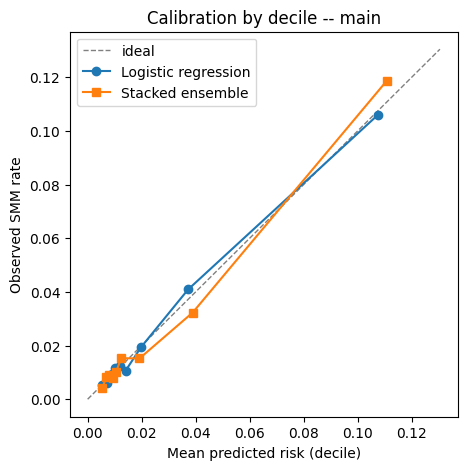

In [8]:
res_main = run_analysis("main", BOOT)

sp = res_main["spec"]; n = len(res_main["y"]); ev = int(res_main["y"].sum())
P_B = count_parameters(sp)
r2_obs = r2cs_from_oof(res_main)

def main_report():
    report(res_main)
    print("\n" + "=" * 110)
    print("MODEL B -- Riley et al. criteria")
    riley_block("Model B (SMM, eligible deliveries)", n, ev, P_B, [("observed (cross-validated LR)", r2_obs)])

emit("main", main_report)
plot_calibration(res_main)

### **9. Model A feasibility -- in-hospital mortality (counts and Riley criteria only; no model is trained)**

> **Framework:** Gate P3 → return R1. Maternal death has too few events; reported as feasibility, and the ladder moves to SMM.

Mortality is reported descriptively in the manuscript. This cell only quantifies what the data can
support: the number of deaths in the eligible populations, and the sample size that Riley's criteria would require
under assumed R2 values, using the same parameter count as Model B.

In [9]:
def model_a_report():
    for lab, mask in [("Eligible deliveries", df.eligible_24h & df.is_delivery_v2),
                      ("Eligible obstetric (any)", df.eligible_24h)]:
        dd = df[mask]
        print(f"{lab}: {len(dd)} admissions, {dd.subject_id.nunique()} patients, deaths in the same admission = {int(dd.died_same_admission.sum())}")
    dd = df[df.eligible_24h & df.is_delivery_v2]
    n_A, ev_A = len(dd), int(dd.died_same_admission.sum())
    phi_A = ev_A / n_A
    lnl0 = phi_A * math.log(phi_A) + (1 - phi_A) * math.log(1 - phi_A)
    max_r2_A = 1 - math.exp(2 * lnl0)
    P_A = count_parameters(make_spec("main"))
    scen = [("15% of max (default)", 0.15 * max_r2_A), ("30% of max", 0.30 * max_r2_A), ("50% of max", 0.50 * max_r2_A)]
    riley_block("Model A (in-hospital mortality, eligible deliveries; ASSUMED R2, no model trained)", n_A, ev_A, P_A, scen)
    print("\nRule of thumb for context: 10 events per candidate parameter would need", 10 * P_A, "deaths;", ev_A, "are available.")

emit("modelA", model_a_report)

Eligible deliveries: 19383 admissions, 13710 patients, deaths in the same admission = 3
Eligible obstetric (any): 23625 admissions, 14602 patients, deaths in the same admission = 5

Model A (in-hospital mortality, eligible deliveries; ASSUMED R2, no model trained): n=19383, events=3, prevalence=0.00015, candidate parameters P=32, EPP=0.09
      R2_CS scenario  R2_CS max R2_CS n shrinkage n optimism n risk(+-0.05) n risk(+-0.01) n required events required  available n  available events max P supported (n,R2)
15% of max (default) 0.0005    0.0030      635433     211800              0              6     635433              98        19383                 3                    1.0
          30% of max 0.0009    0.0030      317637     211752              0              6     317637              49        19383                 3                    2.0
          50% of max 0.0015    0.0030      190518     211688              0              6     211688              33        19383             

### **10. Sensitivity analyses (run one at a time; paste each output)**

> **Framework:** E9 Sensitivity and robustness (alternative populations, definitions and predictor sets).

Each cell refits the whole nested procedure on a different population or feature set (section 3) using `BOOT_SENS`
bootstrap replicates. They do not change the main analysis.

In [10]:
res_first = run_analysis("first_admission", BOOT_SENS)
emit("first_admission", lambda: report(res_first))

[first_admission] first outer fold took 1.5 min -> projected total about 22 min
[first_admission] cross-validation finished in 19.1 min; every admission scored exactly once per repeat: True
  bootstrap: 5 replicates took 2 s -> projected 2.0 min for B=300
ANALYSIS first_admission: 13701 admissions, 13701 patients, 356 events (2.60%), numeric=3, binary=1, categorical=5
Repeats=3, outer folds=5, inner folds=3, bootstrap B=300, QUICK=False

[0] Patients per outer partition (repeat 1 shown; every split verified to share no patient between training and test)
 fold  train_adm  train_pat  train_events  train_event_pat  test_adm  test_pat  test_events  test_event_pat  shared_patients
    1      10961      10961           298              298      2740      2740           58              58                0
    2      10961      10961           281              281      2740      2740           75              75                0
    3      10960      10960           282              282      2

In [11]:
res_anyob = run_analysis("any_obstetric", BOOT_SENS)
emit("any_obstetric", lambda: report(res_anyob))

[any_obstetric] first outer fold took 1.8 min -> projected total about 27 min
[any_obstetric] cross-validation finished in 23.7 min; every admission scored exactly once per repeat: True
  bootstrap: 5 replicates took 3 s -> projected 2.9 min for B=300
ANALYSIS any_obstetric: 23625 admissions, 14602 patients, 814 events (3.45%), numeric=3, binary=1, categorical=5
Repeats=3, outer folds=5, inner folds=3, bootstrap B=300, QUICK=False

[0] Patients per outer partition (repeat 1 shown; every split verified to share no patient between training and test)
 fold  train_adm  train_pat  train_events  train_event_pat  test_adm  test_pat  test_events  test_event_pat  shared_patients
    1      18732      11689           657              601      4893      2913          157             144                0
    2      18959      11689           646              592      4666      2913          168             153                0
    3      18970      11679           651              592      4655   

In [12]:
res_labs = run_analysis("labs_extended", BOOT_SENS)
emit("labs_extended", lambda: report(res_labs))

[labs_extended] first outer fold took 1.7 min -> projected total about 25 min
[labs_extended] cross-validation finished in 23.1 min; every admission scored exactly once per repeat: True
  bootstrap: 5 replicates took 2 s -> projected 2.5 min for B=300
ANALYSIS labs_extended: 19383 admissions, 13710 patients, 445 events (2.30%), numeric=14, binary=12, categorical=5
Repeats=3, outer folds=5, inner folds=3, bootstrap B=300, QUICK=False

[0] Patients per outer partition (repeat 1 shown; every split verified to share no patient between training and test)
 fold  train_adm  train_pat  train_events  train_event_pat  test_adm  test_pat  test_events  test_event_pat  shared_patients
    1      15538      10978           364              360      3845      2732           81              80                0
    2      15518      10967           335              331      3865      2743          110             109                0
    3      15522      10963           356              352      3861 

In [13]:
res_icu = run_analysis("icu_vars", BOOT_SENS)
emit("icu_vars", lambda: report(res_icu))

[icu_vars] first outer fold took 1.8 min -> projected total about 27 min
[icu_vars] cross-validation finished in 22.3 min; every admission scored exactly once per repeat: True
  bootstrap: 5 replicates took 2 s -> projected 2.2 min for B=300
ANALYSIS icu_vars: 19383 admissions, 13710 patients, 445 events (2.30%), numeric=17, binary=16, categorical=5
Repeats=3, outer folds=5, inner folds=3, bootstrap B=300, QUICK=False

[0] Patients per outer partition (repeat 1 shown; every split verified to share no patient between training and test)
 fold  train_adm  train_pat  train_events  train_event_pat  test_adm  test_pat  test_events  test_event_pat  shared_patients
    1      15538      10978           364              360      3845      2732           81              80                0
    2      15518      10967           335              331      3865      2743          110             109                0
    3      15522      10963           356              352      3861      2747      

In [8]:
res_ge2 = run_analysis("label_ge2", BOOT_SENS)
emit("label_ge2", lambda: report(res_ge2))

[label_ge2] first outer fold took 1.0 min -> projected total about 14 min
[label_ge2] cross-validation finished in 11.9 min; every admission scored exactly once per repeat: True
  bootstrap: 5 replicates took 1 s -> projected 1.0 min for B=300
ANALYSIS label_ge2: 19383 admissions, 13710 patients, 129 events (0.67%), numeric=3, binary=1, categorical=5
Repeats=3, outer folds=5, inner folds=3, bootstrap B=300, QUICK=False

[0] Patients per outer partition (repeat 1 shown; every split verified to share no patient between training and test)
 fold  train_adm  train_pat  train_events  train_event_pat  test_adm  test_pat  test_events  test_event_pat  shared_patients
    1      15497      10967           106              105      3886      2743           23              23                0
    2      15479      10969           108              107      3904      2741           21              21                0
    3      15563      10966           101              101      3820      2744     

In [9]:
res_noicu = run_analysis("no_icu_24h", BOOT_SENS)
emit("no_icu_24h", lambda: report(res_noicu))

[no_icu_24h] first outer fold took 0.6 min -> projected total about 10 min
[no_icu_24h] cross-validation finished in 10.8 min; every admission scored exactly once per repeat: True
  bootstrap: 5 replicates took 1 s -> projected 1.0 min for B=300
ANALYSIS no_icu_24h: 19268 admissions, 13632 patients, 355 events (1.84%), numeric=3, binary=1, categorical=5
Repeats=3, outer folds=5, inner folds=3, bootstrap B=300, QUICK=False

[0] Patients per outer partition (repeat 1 shown; every split verified to share no patient between training and test)
 fold  train_adm  train_pat  train_events  train_event_pat  test_adm  test_pat  test_events  test_event_pat  shared_patients
    1      15439      10903           296              295      3829      2729           59              57                0
    2      15439      10906           285              282      3829      2726           70              70                0
    3      15375      10906           276              273      3893      2726  

In [10]:
res_icd10 = run_analysis("icd10_only", BOOT_SENS)
emit("icd10_only", lambda: report(res_icd10))

[icd10_only] first outer fold took 0.5 min -> projected total about 8 min
[icd10_only] cross-validation finished in 8.0 min; every admission scored exactly once per repeat: True
  bootstrap: 5 replicates took 1 s -> projected 0.6 min for B=300
ANALYSIS icd10_only: 8864 admissions, 7070 patients, 271 events (3.06%), numeric=3, binary=1, categorical=5
Repeats=3, outer folds=5, inner folds=3, bootstrap B=300, QUICK=False

[0] Patients per outer partition (repeat 1 shown; every split verified to share no patient between training and test)
 fold  train_adm  train_pat  train_events  train_event_pat  test_adm  test_pat  test_events  test_event_pat  shared_patients
    1       7062       5653           219              218      1802      1417           52              50                0
    2       7118       5656           219              217      1746      1414           52              51                0
    3       7078       5656           217              214      1786      1414      